# E8 · Full-data training on 2× T4 (Kaggle)

E8 trains the best configuration so far (E3) on the **full VRSBench caption train split** and folds in the ideas of E4 and E5,
with two fixes that make a long fp16 run on T4 GPUs possible.

| | E3 (best so far) | **E8** | Why |
|---|---|---|---|
| Train images | 2,000 | **20,264 (all)** | Biggest remaining lever for content *and* for learning when a caption should be short or long (length correlation is only 0.22–0.32 now) |
| LoRA | LLM q/k/v/o + all 32 ViT blocks, r = 16 | same | E3 won on BERT-BLEU₄ |
| Effective batch | 1 | **8** (1 × 4 accumulation × 2 GPUs) | Batch 1 gradients are very noisy (E5 idea); gradient noise variance ∝ 1/batch |
| LR (LLM / ViT) | 5e-5 / 1e-5, constant | **1e-4 / 2e-5**, 3% warmup + cosine | 8× fewer optimizer steps ⇒ larger LR (~√8×, rounded down); warmup + decay from E4 |
| Precision | fp16, no loss scaling | **fp16 base + fp32 LoRA + GradScaler** | E4 and E6 crashed with a non-finite loss (below) |
| GPUs | 1 T4 | **2 T4 (DDP)** | ~2× throughput |
| Snapshots | final only | **25 / 50 / 75 / 100%** | Score-vs-data curve from a single run |

### Why E4 and E6 crashed

T4 GPUs have no bf16, so the model runs in fp16, whose largest value is 65,504 and whose smallest normal value is ~6e-5.
E0–E6 trained in fp16 **without loss scaling**:

- small gradients underflow to 0 and silently stop learning;
- a rare large activation overflows to `inf`, the loss becomes non-finite, and the old training loop did `break`.
  E4 stopped at step 1690 of 2000. Its reported train loss of 1.376 is an artifact: the loss sum over 1,690 steps was divided by 2,000.

**GradScaler** multiplies the loss by a scale S before backward, so small gradients stay representable, and divides them by S
before the optimizer step. If any gradient is `inf`/`NaN`, that single step is skipped and S is halved: the run continues
instead of dying. The number of skipped steps is logged; if 20 steps in a row are skipped, training stops with a hint
(`--vision-fp32` runs the ViT in fp32, which is slower but cannot overflow in fp16).

### How DDP uses both GPUs

`torchrun` starts one process per GPU. Each holds a full model copy (7.5 GB fp16 + activations fits in 15 GB, as E3 showed)
and trains on its own half of the data (`DistributedSampler`). After backward, the LoRA gradients are averaged across the
two GPUs, so both copies take the identical update. With gradient accumulation, that sync is only needed once per optimizer
step, so the other 3 of every 4 backward passes run under `no_sync()` and skip it.

### Time budget

E3 ran at ~0.82 s/image on one T4 (27.4 min / 2,000 images) → 20,264 images ≈ 4.6 h on one GPU, **≈ 2.5–3 h on two**.
The smoke test below measures the real speed first. A Kaggle session allows 12 h. Use **Save Version → Save & Run All**
to run it in the background.

In [1]:
!pip install -q -U transformers accelerate peft qwen-vl-utils

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 74.6 MB/s eta 0:00:00:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 20.5 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 516.0/516.0 kB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 56.4 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 39.6 MB/s eta 0:00:00:00:0100:01


## 1. Paths and data

In [2]:
import json
from pathlib import Path

import numpy as np
import torch

# =====================================================================
# Paths: edit these
# =====================================================================
DATA_ROOT = Path('/kaggle/working/VRSBench')
TRAIN_JSON = DATA_ROOT / 'hf_files' / 'VRSBench_train.json'
TRAIN_IMAGE_DIR = DATA_ROOT / 'Images_train'
OUT_DIR = Path('/kaggle/working/E8')

RECORDS = OUT_DIR / 'train_records.json'
NUM_GPUS = torch.cuda.device_count()
OUT_DIR.mkdir(parents=True, exist_ok=True)
print('GPUs:', NUM_GPUS, [torch.cuda.get_device_name(i) for i in range(NUM_GPUS)])

GPUs: 2 ['Tesla T4', 'Tesla T4']


In [3]:
# Download the train annotations + images once (skipped if already present)
if not TRAIN_JSON.exists() or not TRAIN_IMAGE_DIR.exists():
    from huggingface_hub import hf_hub_download
    from zipfile import ZipFile
    hf_hub_download('xiang709/VRSBench', 'VRSBench_train.json', repo_type='dataset', local_dir=TRAIN_JSON.parent)
    train_zip = hf_hub_download('xiang709/VRSBench', 'Images_train.zip', repo_type='dataset', local_dir=TRAIN_JSON.parent)
    TRAIN_IMAGE_DIR.mkdir(parents=True, exist_ok=True)
    with ZipFile(train_zip) as z:
        z.extractall(TRAIN_IMAGE_DIR)
    Path(train_zip).unlink()

VRSBench_train.json:   0%|          | 0.00/64.9M [00:00<?, ?B/s]

Images_train.zip:   0%|          | 0.00/8.36G [00:00<?, ?B/s]

The train JSON mixes tasks (captioning, VQA, grounding). Caption examples are the ones whose question contains `[caption]`:
20,264 of 142,390 records. Each becomes `{image_id, caption, image_path}`, and the training script reads this list.

In [4]:
train_raw = json.loads(TRAIN_JSON.read_text())
image_path = {p.name: str(p) for p in TRAIN_IMAGE_DIR.rglob('*') if p.suffix.lower() in {'.png', '.jpg', '.jpeg'}}

records = []
for r in train_raw:
    turns = r.get('conversations', [])
    question = next((t['value'] for t in turns if t.get('from') == 'human'), '')
    caption = next((t['value'] for t in reversed(turns) if t.get('from') == 'gpt'), None)
    name = Path(r.get('image', '')).name
    if '[caption]' in question.lower() and caption and name in image_path:
        records.append({'image_id': name, 'caption': caption.strip(), 'image_path': image_path[name]})

RECORDS.write_text(json.dumps(records))
lengths = np.array([len(r['caption'].split()) for r in records])
print(f'{len(records):,} caption records -> {RECORDS}')
print(f'caption words: mean {lengths.mean():.1f} | median {np.median(lengths):.0f} | '
      f'5-95% {np.percentile(lengths, 5):.0f}-{np.percentile(lengths, 95):.0f}')

20,264 caption records -> /kaggle/working/E8/train_records.json
caption words: mean 53.0 | median 52 | 5-95% 26-85


### Base model

Only the LoRA adapter is trained; the frozen base model (Qwen2.5-VL-3B-Instruct, ~7.5 GB) comes from the Hugging Face Hub
(**Internet must be ON** in the Kaggle notebook settings). It is downloaded once here, so the two `torchrun` processes both load
it from the local cache instead of downloading it at the same time.

In [5]:
from huggingface_hub import snapshot_download

MODEL_PATH = snapshot_download('Qwen/Qwen2.5-VL-3B-Instruct')
print('base model at', MODEL_PATH)

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

base model at /root/.cache/huggingface/hub/models--Qwen--Qwen2.5-VL-3B-Instruct/snapshots/66285546d2b821cf421d4f5eb2576359d3770cd3


## 2. Training script

The script is written to a file because `torchrun` must launch it as separate processes, one per GPU.
Its sections:

| Section | What it does |
|---|---|
| Config | every hyperparameter, with the reason next to it |
| `setup_distributed` | reads the rank/world size set by `torchrun`; also runs as a plain single-GPU script |
| `CaptionCollator` | same chat format, prompt and label masking as E0–E5: loss only on the caption tokens |
| `build_model` | fp16 base, E3's LoRA targets, LoRA weights forced to fp32 |
| training loop | gradient accumulation + `no_sync`, GradScaler, gradient clipping, warmup + cosine LR, logging, snapshots |
| summary | `metrics_E8.json` in the same format as the E0–E5 metrics files |

In [6]:
%%writefile train_e8.py
"""
E8 - full-data LoRA fine-tuning of Qwen2.5-VL-3B on VRSBench captions.

Same model, prompt, image budget and LoRA targets as E3 (the best run so far), plus:
  - the full caption train split (~20k) instead of 2k
  - gradient accumulation (effective batch 8) + warmup/cosine LR (E4, E5 ideas)
  - fp16 loss scaling (GradScaler) so an overflow skips one step instead of killing the run (E4, E6 crashed)
  - DistributedDataParallel: one model copy per GPU, each GPU trains on half the data

Launch (2 GPUs):  torchrun --nproc_per_node=2 train_e8.py --records train_records.json --out /kaggle/working/E8
Launch (1 GPU):   python train_e8.py --records train_records.json --out /kaggle/working/E8
"""

import argparse
import json
import math
import os
import random
import time
from contextlib import nullcontext
from datetime import timedelta
from pathlib import Path

import numpy as np
import torch
import torch.distributed as dist
from peft import LoraConfig, get_peft_model
from qwen_vl_utils import process_vision_info
from torch.nn.parallel import DistributedDataParallel as DDP
from torch.utils.data import DataLoader, DistributedSampler
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration, get_cosine_schedule_with_warmup

os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')


# ---------------------------------------------------------------------------
# Config
# ---------------------------------------------------------------------------

MODEL_ID = 'Qwen/Qwen2.5-VL-3B-Instruct'
PROMPT = 'Describe the image in detail.'   # identical to E0-E5 and the eval notebook
MIN_PIXELS = 224 * 224
MAX_PIXELS = 448 * 448                      # 256 visual tokens; E1 showed more pixels = 2.4x time, no gain

LORA_R, LORA_ALPHA, LORA_DROPOUT = 16, 32, 0.05
LLM_TARGETS = ['q_proj', 'k_proj', 'v_proj', 'o_proj']
VISION_TARGETS = [f'model.visual.blocks.{i}.attn.{m}' for i in range(32) for m in ('qkv', 'proj')]  # E3: all 32 ViT blocks

LR_LLM = 1e-4             # E3 used 5e-5 at batch 1; batch 8 means 8x fewer steps, so LR goes up (~sqrt(8), rounded down)
LR_VISION = 2e-5          # kept 5x lower than the LLM: the ViT is already aligned with the LLM (paper, stage 1-2)
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.03       # first 3% of steps ramp the LR up from 0
GRAD_ACCUM = 4            # per GPU -> effective batch = 1 image x 4 steps x 2 GPUs = 8
MAX_GRAD_NORM = 1.0
EPOCHS = 1                # E6 (2 epochs) was unstable, and time is limited
SAVE_FRACTIONS = (0.25, 0.5, 0.75)   # extra adapter snapshots -> "score vs data seen" curve
LOG_EVERY = 25            # optimizer steps
MAX_SKIPS_IN_A_ROW = 20   # fp16 overflowing this often means training has diverged -> stop
NUM_WORKERS = 2           # CPU workers that load + preprocess images while the GPU trains
SEED = 42


# ---------------------------------------------------------------------------
# Setup
# ---------------------------------------------------------------------------

def parse_args():
    p = argparse.ArgumentParser()
    p.add_argument('--records', required=True, help='train_records.json written by the notebook')
    p.add_argument('--out', required=True, help='folder for adapters and logs')
    p.add_argument('--model', default=MODEL_ID)
    p.add_argument('--max-samples', type=int, default=None, help='train on a random subset (time budget)')
    p.add_argument('--smoke', action='store_true', help='64 samples only: checks the pipeline, memory and speed')
    p.add_argument('--vision-fp32', action='store_true', help='run the ViT in fp32 if fp16 keeps overflowing (slower)')
    return p.parse_args()


def setup_distributed():
    """torchrun sets RANK / LOCAL_RANK / WORLD_SIZE. Plain `python` gives a single-process run."""
    use_cuda = torch.cuda.is_available()
    if 'RANK' in os.environ:
        dist.init_process_group('nccl' if use_cuda else 'gloo', timeout=timedelta(minutes=60))
        rank, world = dist.get_rank(), dist.get_world_size()
    else:
        rank, world = 0, 1
    local_rank = int(os.environ.get('LOCAL_RANK', 0))
    if use_cuda:
        torch.cuda.set_device(local_rank)
        return rank, world, torch.device('cuda', local_rank)
    return rank, world, torch.device('cpu')


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


# ---------------------------------------------------------------------------
# Data
# ---------------------------------------------------------------------------

def find_subsequence(sequence, pattern):
    for i in range(len(sequence) - len(pattern) + 1):
        if sequence[i:i + len(pattern)] == pattern:
            return i
    return -1


class CaptionCollator:
    """Turns (image, caption) records into one batch; the loss is computed on caption tokens only."""

    def __init__(self, processor):
        self.processor = processor
        self.assistant_marker = processor.tokenizer('<|im_start|>assistant\n', add_special_tokens=False)['input_ids']

    def __call__(self, examples):
        conversations = [[
            {'role': 'user', 'content': [{'type': 'image', 'image': ex['image_path']},
                                         {'type': 'text', 'text': PROMPT}]},
            {'role': 'assistant', 'content': ex['caption']},
        ] for ex in examples]

        texts = [self.processor.apply_chat_template(c, tokenize=False, add_generation_prompt=False)
                 for c in conversations]
        images, videos = process_vision_info(conversations)
        batch = self.processor(text=texts, images=images, videos=videos, padding=True, return_tensors='pt')

        labels = batch['input_ids'].clone()
        for i, row in enumerate(batch['input_ids'].tolist()):
            start = find_subsequence(row, self.assistant_marker)
            if start == -1:
                raise RuntimeError('assistant marker not found in the tokenized conversation')
            labels[i, :start + len(self.assistant_marker)] = -100   # system + user prompt + image tokens
        labels[batch['attention_mask'] == 0] = -100                  # padding
        batch['labels'] = labels
        return batch


def to_device(batch, device):
    return {k: v.to(device, non_blocking=True) if torch.is_tensor(v) else v for k, v in batch.items()}


# ---------------------------------------------------------------------------
# Model
# ---------------------------------------------------------------------------

def build_model(model_id, device, vision_fp32):
    # T4 has no bf16, so the frozen base weights are fp16 (7.5 GB instead of 15 GB in fp32)
    dtype = torch.float16 if device.type == 'cuda' else torch.float32
    model = Qwen2_5_VLForConditionalGeneration.from_pretrained(model_id, dtype=dtype, attn_implementation='sdpa')
    if vision_fp32:
        model.model.visual.float()   # the model casts pixel_values / image features to the right dtype itself
    model.config.use_cache = False   # KV cache is only useful for generation

    lora = LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT,
                      target_modules=VISION_TARGETS + LLM_TARGETS, bias='none', task_type='CAUSAL_LM')
    model = get_peft_model(model, lora)

    # LoRA weights must be fp32: GradScaler cannot unscale fp16 gradients, and fp32 keeps tiny updates from rounding away
    for p in model.parameters():
        if p.requires_grad:
            p.data = p.data.float()
    return model.to(device)


def make_optimizer(model):
    vision, llm = [], []
    for name, p in model.named_parameters():
        if p.requires_grad:
            (vision if '.visual.' in name else llm).append(p)
    return torch.optim.AdamW([
        {'params': vision, 'lr': LR_VISION},
        {'params': llm, 'lr': LR_LLM},
    ], weight_decay=WEIGHT_DECAY)


# ---------------------------------------------------------------------------
# Training
# ---------------------------------------------------------------------------

def main():
    args = parse_args()
    rank, world, device = setup_distributed()
    is_main = rank == 0
    log = (lambda *a: print(*a, flush=True)) if is_main else (lambda *a: None)
    seed_everything(SEED)

    out = Path(args.out) / ('smoke' if args.smoke else '')
    out.mkdir(parents=True, exist_ok=True)

    # ---- data ----
    records = json.loads(Path(args.records).read_text())
    if args.max_samples:
        records = random.Random(SEED).sample(records, args.max_samples)
    if args.smoke:
        records = records[:64]
    log(f'training on {len(records):,} captions across {world} process(es) on {device.type}')

    processor = AutoProcessor.from_pretrained(args.model, min_pixels=MIN_PIXELS, max_pixels=MAX_PIXELS)
    processor.tokenizer.padding_side = 'right'
    sampler = DistributedSampler(records, num_replicas=world, rank=rank, shuffle=True, seed=SEED)
    loader = DataLoader(records, batch_size=1, sampler=sampler, collate_fn=CaptionCollator(processor),
                        num_workers=NUM_WORKERS, pin_memory=device.type == 'cuda',
                        persistent_workers=NUM_WORKERS > 0)

    # ---- model ----
    model = build_model(args.model, device, args.vision_fp32)
    trainable = [p for p in model.parameters() if p.requires_grad]
    log(f'trainable LoRA params: {sum(p.numel() for p in trainable):,}')
    if world > 1:
        model = DDP(model, device_ids=[device.index] if device.type == 'cuda' else None)
    core = model.module if world > 1 else model   # the PEFT model, for saving

    optimizer = make_optimizer(core)
    total_steps = math.ceil(len(loader) / GRAD_ACCUM) * EPOCHS
    scheduler = get_cosine_schedule_with_warmup(optimizer, math.ceil(WARMUP_RATIO * total_steps), total_steps)
    # Loss scaling: multiply the loss before backward so small fp16 gradients don't underflow to 0.
    # If any gradient overflows to inf/NaN, scaler.step() skips that update and lowers the scale.
    scaler = torch.amp.GradScaler('cuda', init_scale=2 ** 12, enabled=device.type == 'cuda')
    save_at = {max(1, round(f * total_steps)): f for f in SAVE_FRACTIONS}
    log_every = 2 if args.smoke else LOG_EVERY

    log(f'{total_steps} optimizer steps | effective batch {GRAD_ACCUM * world} | '
        f'LR llm {LR_LLM} / vision {LR_VISION} | warmup {math.ceil(WARMUP_RATIO * total_steps)} steps')

    history, window = [], []
    step, skipped, skipped_in_a_row = 0, 0, 0
    stop = False
    if device.type == 'cuda':
        torch.cuda.reset_peak_memory_stats(device)
    model.train()
    start = time.perf_counter()

    for epoch in range(EPOCHS):
        sampler.set_epoch(epoch)   # a different shuffle every epoch, identical on all GPUs
        for i, batch in enumerate(loader):
            is_update_step = (i + 1) % GRAD_ACCUM == 0 or i + 1 == len(loader)
            # Between updates, skip the cross-GPU gradient sync: it only has to happen once per optimizer step
            sync = nullcontext() if (world == 1 or is_update_step) else model.no_sync()
            with sync:
                loss = model(**to_device(batch, device)).loss
                # Always call backward, even on a NaN loss: both GPUs must run the same ops or DDP hangs.
                # A NaN loss gives NaN gradients, and the scaler then skips the update.
                scaler.scale(loss / GRAD_ACCUM).backward()
            if torch.isfinite(loss):
                window.append(loss.item())

            if not is_update_step:
                continue

            scaler.unscale_(optimizer)
            grad_norm = torch.nn.utils.clip_grad_norm_(trainable, MAX_GRAD_NORM)
            scale_before = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()
            step += 1
            seen = (epoch * len(loader) + i + 1) * world   # images processed so far, all GPUs together

            if scaler.get_scale() < scale_before:   # the update was skipped
                skipped += 1
                skipped_in_a_row += 1
                if skipped_in_a_row >= MAX_SKIPS_IN_A_ROW:
                    log(f'stopping: {skipped_in_a_row} overflowing steps in a row at step {step} '
                        f'(try --vision-fp32 or a lower LR)')
                    stop = True
                    break
            else:
                skipped_in_a_row = 0

            if step % log_every == 0 or step == total_steps:
                elapsed = time.perf_counter() - start
                entry = {
                    'step': step,
                    'samples_seen': seen,
                    'loss': float(np.mean(window)) if window else float('nan'),
                    'lr_llm': scheduler.get_last_lr()[1],
                    'grad_norm': float(grad_norm),
                    'loss_scale': scaler.get_scale(),
                    'skipped_steps': skipped,
                    'samples_per_sec': seen / elapsed,
                    'elapsed_min': elapsed / 60,
                }
                history.append(entry)
                window = []
                eta = elapsed / step * (total_steps - step) / 60
                log(f"step {step:5d}/{total_steps} | loss {entry['loss']:.4f} | lr {entry['lr_llm']:.2e} | "
                    f"grad {entry['grad_norm']:.2f} | {entry['samples_per_sec']:.2f} img/s | "
                    f"skipped {skipped} | {entry['elapsed_min']:.1f} min, ETA {eta:.0f} min")
                if is_main:
                    (out / 'train_log.json').write_text(json.dumps(history, indent=1))

            if step in save_at and is_main:
                path = out / f'checkpoint-{int(save_at[step] * 100)}pct'
                core.save_pretrained(path)
                log(f'saved {path.name} ({seen:,} images seen)')
        if stop:
            break

    # ---- summary ----
    train_time = time.perf_counter() - start
    peak = torch.tensor(torch.cuda.max_memory_allocated(device) / 1024 ** 3 if device.type == 'cuda' else 0.0,
                        device=device)
    if world > 1:
        dist.all_reduce(peak, op=dist.ReduceOp.MAX)

    if is_main:
        core.save_pretrained(out / 'final')
        metrics = {
            'config': {
                'model': args.model, 'train_samples': len(records), 'epochs': EPOCHS, 'gpus': world,
                'batch_size': 1, 'grad_accum_per_gpu': GRAD_ACCUM, 'effective_batch': GRAD_ACCUM * world,
                'learning_rate': {'vision_params': LR_VISION, 'llm_params': LR_LLM},
                'schedule': f'cosine, {WARMUP_RATIO:.0%} warmup', 'lora_r': LORA_R, 'lora_alpha': LORA_ALPHA,
                'lora_dropout': LORA_DROPOUT, 'min_pixels': MIN_PIXELS, 'max_pixels': MAX_PIXELS,
                'precision': 'fp16 base + fp32 LoRA + GradScaler' + (', fp32 ViT' if args.vision_fp32 else ''),
            },
            'training': [{
                'epoch': EPOCHS,
                'train_loss': history[-1]['loss'] if history else None,
                'val_loss': None,
                'epoch_time_min': train_time / 60,
                'peak_gpu_memory_gb': peak.item(),
                'optimizer_steps': step,
                'skipped_steps': skipped,
                'samples_per_sec': len(records) / train_time,
            }],
        }
        (out / 'metrics_E8.json').write_text(json.dumps(metrics, indent=2))
        log(f'done in {train_time / 60:.1f} min | peak GPU memory {peak.item():.2f} GB | '
            f'{len(records) / train_time:.2f} img/s | skipped {skipped}/{step} steps | saved to {out}')

    if world > 1:
        dist.barrier()
        dist.destroy_process_group()


if __name__ == '__main__':
    main()

Writing train_e8.py


## 3. Smoke test (~3 min)

Trains on 64 images only. Check three things before the long run:

1. it finishes without errors on both GPUs;
2. **peak GPU memory** stays below ~14 GB (T4 has 15 GB);
3. **img/s**: `20,264 / img/s` gives the full-run time. This is a slight underestimate of speed, because the first steps include warm-up.

In [10]:
!pip install -q -U torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 48.8 MB/s eta 0:00:00:00:01


In [11]:
!torchrun --nproc_per_node={NUM_GPUS} train_e8.py --model {MODEL_PATH} --records {RECORDS} --out {OUT_DIR} --smoke

W0930 10:51:18.074000 227 torch/distributed/run.py:852] 
W0930 10:51:18.074000 227 torch/distributed/run.py:852] *****************************************
W0930 10:51:18.074000 227 torch/distributed/run.py:852] Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
W0930 10:51:18.074000 227 torch/distributed/run.py:852] *****************************************
Skipping import of cpp extensions due to incompatible torch version. Please upgrade to torch >= 2.11.0 (found 2.10.0+cu128).
Skipping import of cpp extensions due to incompatible torch version. Please upgrade to torch >= 2.11.0 (found 2.10.0+cu128).
training on 64 captions across 2 process(es) on cuda
The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking

## 4. Full run

Short on time? Add `--max-samples 10000` to train on a random half (~1.5 h). The snapshots still give a data-scaling curve.

In [12]:
!torchrun --nproc_per_node={NUM_GPUS} train_e8.py --model {MODEL_PATH} --records {RECORDS} --out {OUT_DIR}

W0930 10:54:09.483000 295 torch/distributed/run.py:852] 
W0930 10:54:09.483000 295 torch/distributed/run.py:852] *****************************************
W0930 10:54:09.483000 295 torch/distributed/run.py:852] Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
W0930 10:54:09.483000 295 torch/distributed/run.py:852] *****************************************
Skipping import of cpp extensions due to incompatible torch version. Please upgrade to torch >= 2.11.0 (found 2.10.0+cu128).
Skipping import of cpp extensions due to incompatible torch version. Please upgrade to torch >= 2.11.0 (found 2.10.0+cu128).
training on 20,264 captions across 2 process(es) on cuda
The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a brea

## 5. Training curves

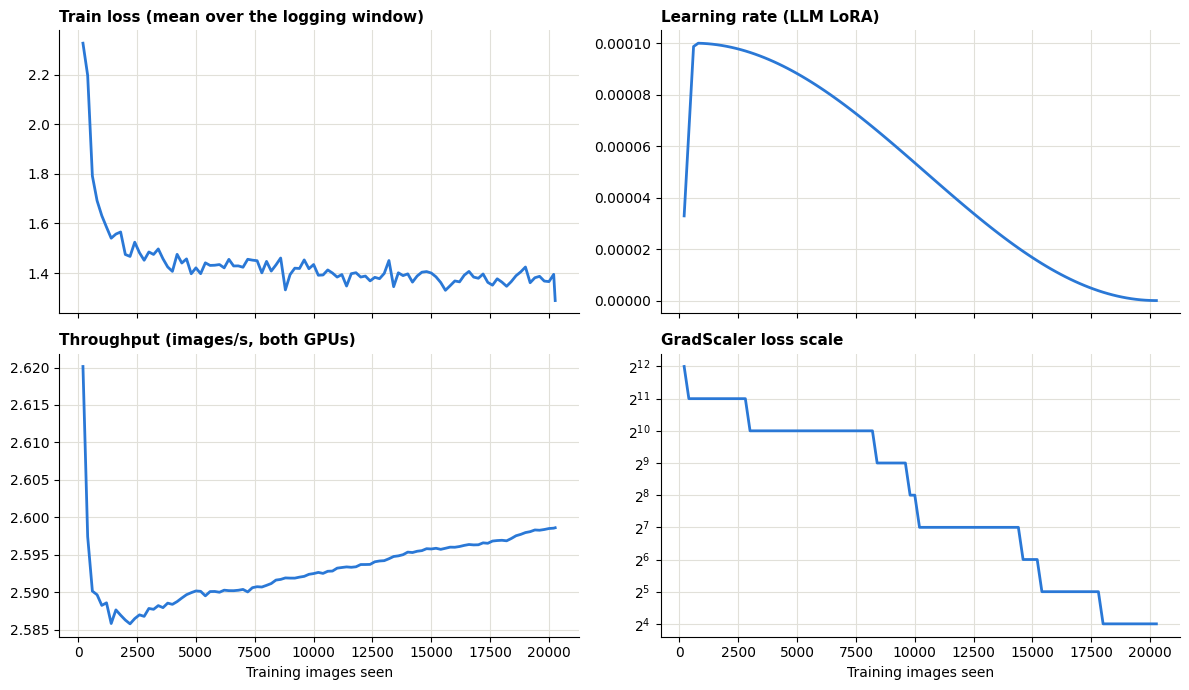

time 130.0 min | 2.60 img/s | peak 12.68 GB/GPU | skipped 8/2533 steps


In [13]:
import matplotlib.pyplot as plt

log = json.loads((OUT_DIR / 'train_log.json').read_text())
seen = [e['samples_seen'] for e in log]
panels = [('loss', 'Train loss (mean over the logging window)'),
          ('lr_llm', 'Learning rate (LLM LoRA)'),
          ('samples_per_sec', 'Throughput (images/s, both GPUs)'),
          ('loss_scale', 'GradScaler loss scale')]

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e1e0d9', 'axes.titleweight': 'bold', 'axes.titlelocation': 'left'})
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, (key, title) in zip(axes.flat, panels):
    ax.plot(seen, [e[key] for e in log], color='#2a78d6', lw=2)
    ax.set_title(title, fontsize=11)
axes[1, 1].set_yscale('log', base=2)
for ax in axes[1]:
    ax.set_xlabel('Training images seen')
fig.tight_layout()
fig.savefig(OUT_DIR / 'training_curves.png', dpi=200)
plt.show()

m = json.loads((OUT_DIR / 'metrics_E8.json').read_text())['training'][0]
print(f"time {m['epoch_time_min']:.1f} min | {m['samples_per_sec']:.2f} img/s | peak {m['peak_gpu_memory_gb']:.2f} GB/GPU | "
      f"skipped {m['skipped_steps']}/{m['optimizer_steps']} steps")

## 6. Next

Outputs in `/kaggle/working/E8/`: `checkpoint-25pct`, `checkpoint-50pct`, `checkpoint-75pct`, `final` (LoRA adapters),
`metrics_E8.json`, `train_log.json`, `training_curves.png`.

Then open `decode_eval.ipynb`, point its `ADAPTERS` at these folders, and run **Phase B** (score vs data) and **Phase C** (final test).